# 04 — Segmentasi Ruang Warna Fisik CIE Lab dan Global K-Means

## Tujuan dan batas analisis

**Pertanyaan:** bagaimana representasi piksel pada ruang warna fisik CIE Lab (`L*`, `a*`, `b*`) dikelompokkan oleh `MiniBatchKMeans` (`k = 2, 3, 4`) pada piksel `train`, dan bagaimana *cluster* dipetakan ke *foreground* tanpa kebocoran data validasi/uji?

**Artefak input:**
- `models/kmeans_lab_k{2,3,4}.json` dan `models/kmeans_lab_k{2,3,4}_mapped.json`
- `configs/provenance_migration.json` dan `configs/otsu_raw.json`
- `data/metadata/split_manifest.csv`
- Opsional: *cache* `data/processed/kmeans_train_pixels.npz` dan citra `train`

**Batas eksekusi:** notebook ini membaca pusat *cluster* dan pemetaan yang sudah dilatih pada `train`; tidak melakukan *resampling*, *refitting* K-means, atau pemetaan berbasis anotasi validasi.

In [1]:
%matplotlib inline

import json
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    PIXEL_CACHE_REL,
    REFERENCE_THRESHOLD,
    compute_histogram_1d,
    compute_shared_lab_edges,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    has_raw_dataset,
    load_kmeans_model,
    load_raw_mask,
    load_reference_mask,
    load_rgb,
    load_split_manifest,
    overlap_scores,
    predict_mask,
    resolve_manifest_path,
    rgb_to_lab,
    sha256_bytes,
    verify_frozen_split,
    verify_helper_provenance,
)

PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
EXPORT_FIGURES = False
TRAIN_EXAMPLE_ID = "Normal/GT2000000-1-400-001"

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
RAW_AVAILABLE = has_raw_dataset(ROOT, data_root_override=DATA_ROOT_OVERRIDE)
CACHE_PATH = ROOT / PIXEL_CACHE_REL
CACHE_AVAILABLE = CACHE_PATH.is_file()
configure_notebook_style()

source_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "provenance_migration": ROOT / "configs/provenance_migration.json",
    "otsu_config": ROOT / "configs/otsu_raw.json",
}
for k in (2, 3, 4):
    source_files[f"fit_k{k}"] = ROOT / f"models/kmeans_lab_k{k}.json"
    source_files[f"mapped_k{k}"] = ROOT / f"models/kmeans_lab_k{k}_mapped.json"
input_hashes_before = {name: sha256_bytes(path) for name, path in source_files.items()}

display(
    pd.DataFrame(
        {
            "komponen": ["Python", "NumPy", "pandas", "Raw dataset tersedia", "Pixel cache (.npz) tersedia"],
            "nilai": [
                platform.python_version(),
                np.__version__,
                pd.__version__,
                str(RAW_AVAILABLE),
                str(CACHE_AVAILABLE),
            ],
        }
    )
)

,komponen,nilai
0,Python,3.14.0
1,NumPy,2.5.4
2,pandas,3.1.1
3,Raw dataset tersedia,True
4,Pixel cache (.npz) tersedia,True


## 1. Provenance artefak model dan verifikasi *cache* sampling `train`

*Fitting* historis mengambil `1.000` posisi piksel acak tanpa pengembalian per citra `train` (`1.535 × 1.000 = 1.535.000` vektor Lab `float32`, `seed = 42`). Saat inferensi, seluruh `224 × 224 = 50.176` piksel citra diklasifikasikan ke pusat *cluster* terdekat menggunakan jarak Euclidean kuadrat `float64`.

In [2]:
split_df = load_split_manifest(ROOT, verify=False)
train_sorted = split_df.loc[split_df["split"].eq("train")].sort_values("sample_id")

fitted_models = {k: json.loads(source_files[f"fit_k{k}"].read_text(encoding="utf-8")) for k in (2, 3, 4)}
mapped_models = {k: load_kmeans_model(ROOT, k=k, verify_provenance=True) for k in (2, 3, 4)}

prov_rows = []
for k in (2, 3, 4):
    fit_sha = input_hashes_before[f"fit_k{k}"]
    assert mapped_models[k]["source_fit_sha256"] == fit_sha
    helper_check = verify_helper_provenance(
        ROOT,
        "kmeans_prediction",
        str(mapped_models[k]["prediction"]["helper_sha256"]),
    )
    prov_rows.append(
        {
            "model": f"k={k}",
            "training_pixels": mapped_models[k]["training_pixel_count"],
            "mean_sq_lab_dist": round(float(mapped_models[k]["fit_diagnostics"]["mean_squared_lab_distance"]), 4),
            "foreground_clusters": str(mapped_models[k]["foreground_clusters"]),
            "fit_source_verified": mapped_models[k]["source_fit_sha256"] == fit_sha,
            "helper_lineage_verified": helper_check["verified"],
        }
    )
display(pd.DataFrame(prov_rows).set_index("model"))

if not CACHE_AVAILABLE:
    display(Markdown("> **Status cache:** `data/processed/kmeans_train_pixels.npz` (Git-ignored) tidak ditemukan; verifikasi *cache* lokal dilewati."))
else:
    cache_sha = sha256_bytes(CACHE_PATH)
    for k in (2, 3, 4):
        assert mapped_models[k]["sample_cache_sha256"] == cache_sha
    with np.load(CACHE_PATH, allow_pickle=False) as cache:
        x_sample = cache["lab_pixels"]
        y_sample = cache["reference_foreground"]
        cached_ids = cache["sample_ids"].tolist()
        sampled_idx = cache["sampled_pixel_indices"]
        assert cache["split_sha256"].item() == SPLIT_SHA
        assert x_sample.shape == (1535000, 3) and x_sample.dtype == np.float32
        assert y_sample.shape == (1535000,) and y_sample.dtype == np.bool_
        assert cached_ids == train_sorted["sample_id"].tolist()
        assert np.all(np.diff(np.sort(sampled_idx, axis=1), axis=1) > 0)
        first_indices = sampled_idx[0].copy()
        first_lab = x_sample[:1000].copy()
        first_ref = y_sample[:1000].copy()

    if RAW_AVAILABLE:
        first_rec = train_sorted.iloc[0]
        raw_img = load_rgb(resolve_manifest_path(ROOT, first_rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
        raw_msk = load_raw_mask(resolve_manifest_path(ROOT, first_rec["mask_path"], data_root_override=DATA_ROOT_OVERRIDE))
        recomputed_lab = rgb_to_lab(raw_img).reshape(-1, 3)[first_indices]
        recomputed_ref = raw_msk.reshape(-1)[first_indices] >= REFERENCE_THRESHOLD
        assert np.array_equal(first_lab, recomputed_lab)
        assert np.array_equal(first_ref, recomputed_ref)
    print(f"Verified pixel cache ({CACHE_PATH.name}): 1,535,000 Lab vectors, sampled FG={100*float(y_sample.mean()):.2f}%.")

,training_pixels,mean_sq_lab_dist,foreground_clusters,fit_source_verified,helper_lineage_verified
model,,,,,
k=2,1535000,578.4137,[1],True,True
k=3,1535000,452.0533,"[0, 2]",True,True
k=4,1535000,314.5659,"[0, 1, 2]",True,True


Verified pixel cache (kmeans_train_pixels.npz): 1,535,000 Lab vectors, sampled FG=63.69%.


## 2. Pusat *cluster* fisik `(L*, a*, b*)` dan aturan pemetaan *foreground*

Konversi menggunakan `RGB uint8 -> float32 / 255 -> cv2.COLOR_RGB2LAB` tanpa penskalaan tambahan, sehingga `L*` berada pada rentang kecerahan fisik `~0–100`, sedangkan `a*` dan `b*` bertanda (*signed*). Sebuah *cluster* dipetakan sebagai *foreground* jika proporsi piksel referensi `train` di dalamnya memenuhi `rate >= 0.5`.

,model,cluster_id,L*,a*,b*,train_pixels,train_ref_fg_rate,mapped_role
0,k=2,0,69.180,18.266,-17.225,514990,0.4442,background
1,k=2,1,34.403,45.670,-50.047,1020010,0.7342,foreground
2,k=3,0,42.570,52.167,-54.923,586363,0.7096,foreground
3,k=3,1,71.557,16.383,-15.633,463543,0.4328,background
4,k=3,2,25.544,35.493,-41.182,485094,0.7441,foreground
5,k=4,0,55.619,30.647,-28.488,444841,0.5410,foreground
6,k=4,1,21.238,41.313,-50.166,477998,0.7866,foreground
7,k=4,2,46.514,54.844,-55.612,387052,0.7054,foreground
8,k=4,3,81.722,5.030,-6.187,225109,0.3909,background


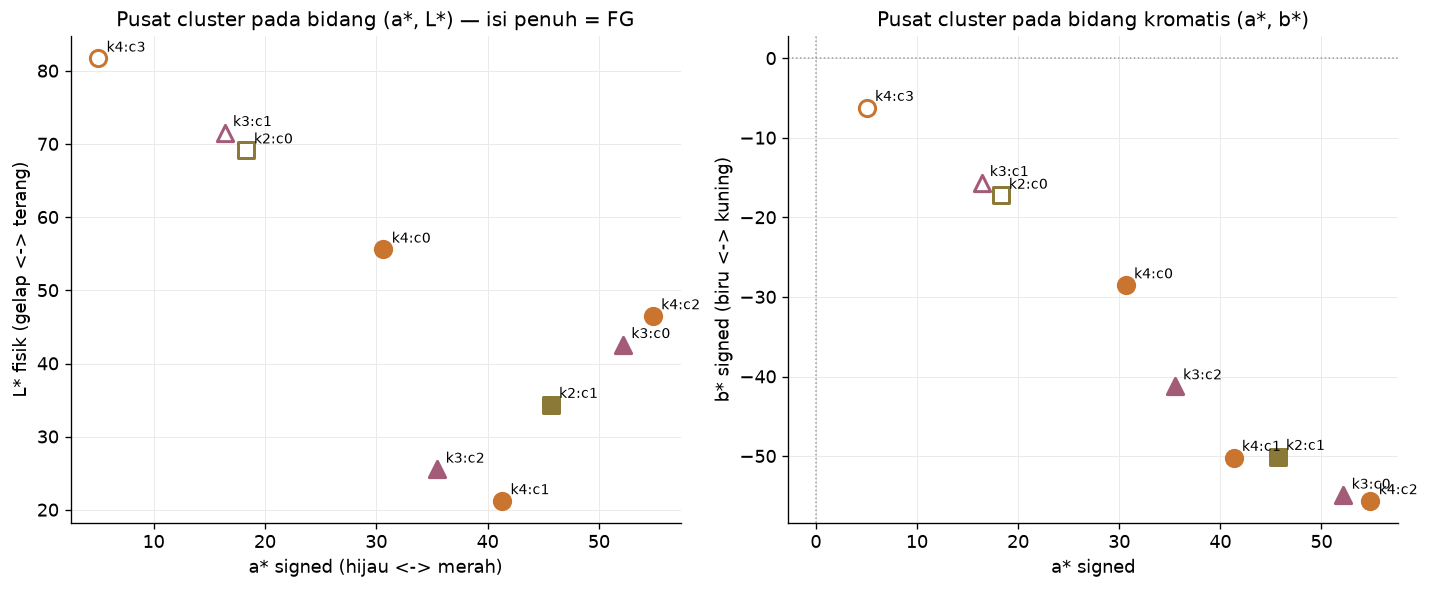

In [3]:
cluster_rows = []
for k, model in mapped_models.items():
    centers = model["cluster_centers"]
    fg_set = set(model["foreground_clusters"])
    mapping = model["foreground_mapping"]
    for cid, (center, px_n, fg_n, fg_rate) in enumerate(
        zip(
            centers,
            mapping["cluster_pixel_counts"],
            mapping["cluster_reference_foreground_counts"],
            mapping["cluster_reference_foreground_rates"],
        )
    ):
        cluster_rows.append(
            {
                "model": f"k={k}",
                "cluster_id": cid,
                "L*": round(float(center[0]), 3),
                "a*": round(float(center[1]), 3),
                "b*": round(float(center[2]), 3),
                "train_pixels": int(px_n),
                "train_ref_fg_rate": round(float(fg_rate), 4),
                "mapped_role": "foreground" if cid in fg_set else "background",
            }
        )
cluster_df = pd.DataFrame(cluster_rows)
display(cluster_df)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.8), layout="constrained")
markers = {2: "s", 3: "^", 4: "o"}
palette = {2: "#8B7938", 3: "#A45B78", 4: "#C97530"}
for k in (2, 3, 4):
    sub = cluster_df.loc[cluster_df["model"].eq(f"k={k}")]
    for _, r in sub.iterrows():
        is_fg = r["mapped_role"] == "foreground"
        face = palette[k] if is_fg else "white"
        axes[0].scatter(r["a*"], r["L*"], s=95, marker=markers[k], facecolor=face, edgecolor=palette[k], linewidth=1.8)
        axes[0].annotate(f"k{k}:c{int(r['cluster_id'])}", (r["a*"], r["L*"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5)
        axes[1].scatter(r["a*"], r["b*"], s=95, marker=markers[k], facecolor=face, edgecolor=palette[k], linewidth=1.8)
        axes[1].annotate(f"k{k}:c{int(r['cluster_id'])}", (r["a*"], r["b*"]), xytext=(5, 4), textcoords="offset points", fontsize=8.5)

axes[0].set_xlabel("a* signed (hijau <-> merah)")
axes[0].set_ylabel("L* fisik (gelap <-> terang)")
axes[0].set_title("Pusat cluster pada bidang (a*, L*) — isi penuh = FG")
axes[0].grid(color="#EAEAEA", linewidth=0.6)

axes[1].axhline(0, color="#999999", linestyle=":", linewidth=0.9)
axes[1].axvline(0, color="#999999", linestyle=":", linewidth=0.9)
axes[1].set_xlabel("a* signed")
axes[1].set_ylabel("b* signed (biru <-> kuning)")
axes[1].set_title("Pusat cluster pada bidang kromatis (a*, b*)")
axes[1].grid(color="#EAEAEA", linewidth=0.6)

export_target = (ROOT / "reports/figures/04_kmeans_lab_centers.png") if EXPORT_FIGURES else None
finish_figure(fig, export_path=export_target)

**Observasi struktur *cluster* Lab.** Pada ketiga nilai `k`, satu *cluster* dengan `L*` paling tinggi (`~79–82`) dan kroma rendah (`a* ≈ 5–7`, `b* ≈ -6` sampai `-8`, khas lumen putih/latar kaca objek) memiliki laju *foreground* `train` di bawah `0.5` sehingga dipetakan ke *background*, sedangkan seluruh *cluster* lain yang lebih gelap dan lebih jenuh warna (`a* > 25`, `b* < -25`) dipetakan ke *foreground*.

## 3. Kanal fisik Lab, histogram, dan contoh inferensi penuh pada citra `train`

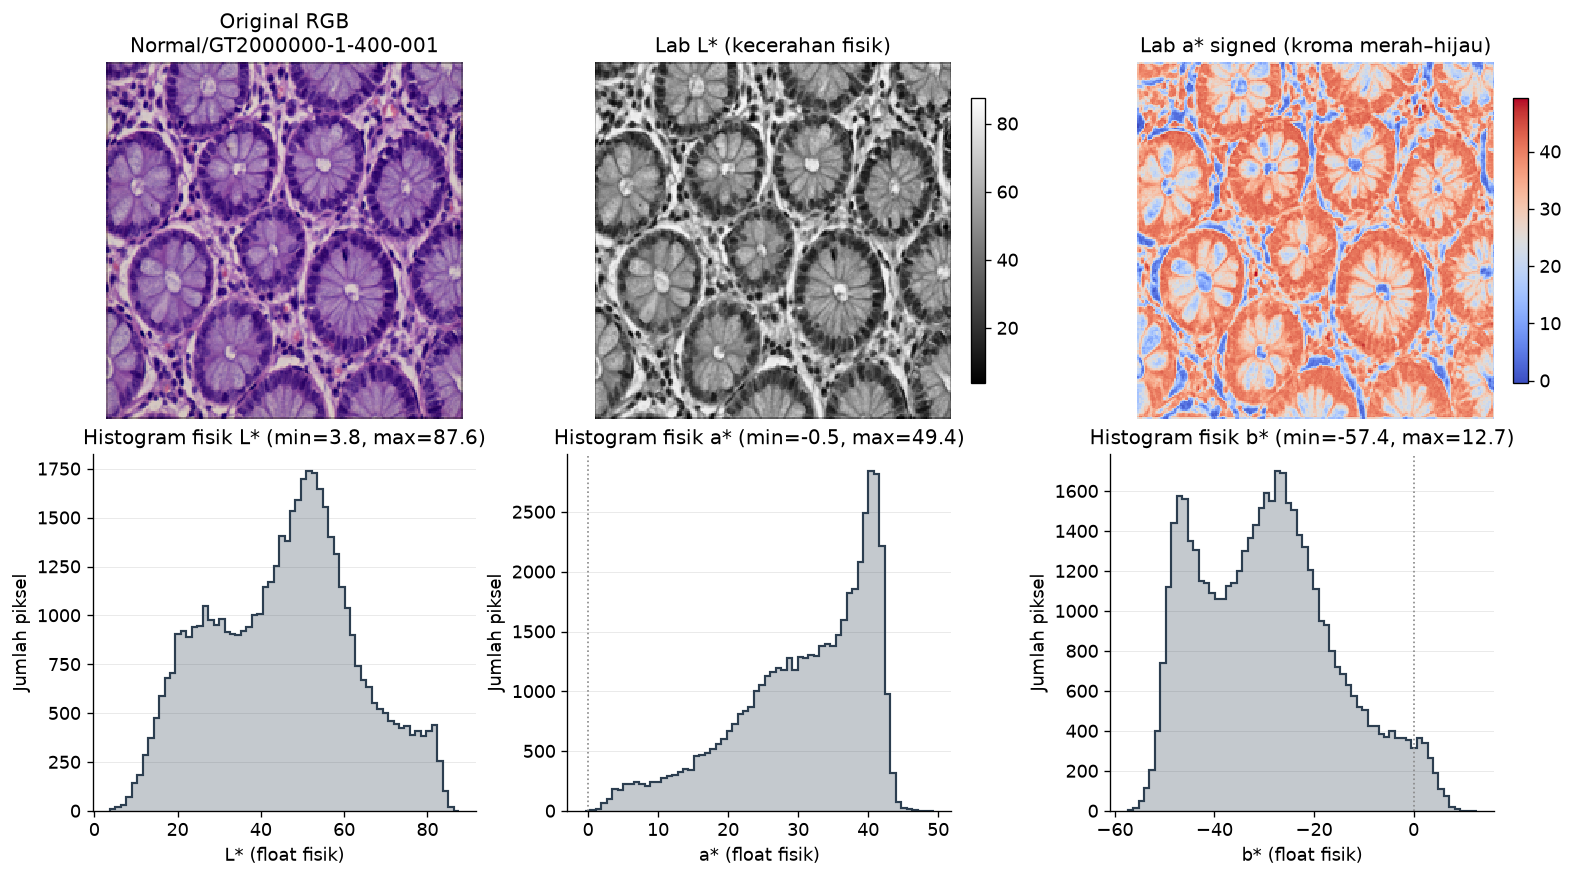

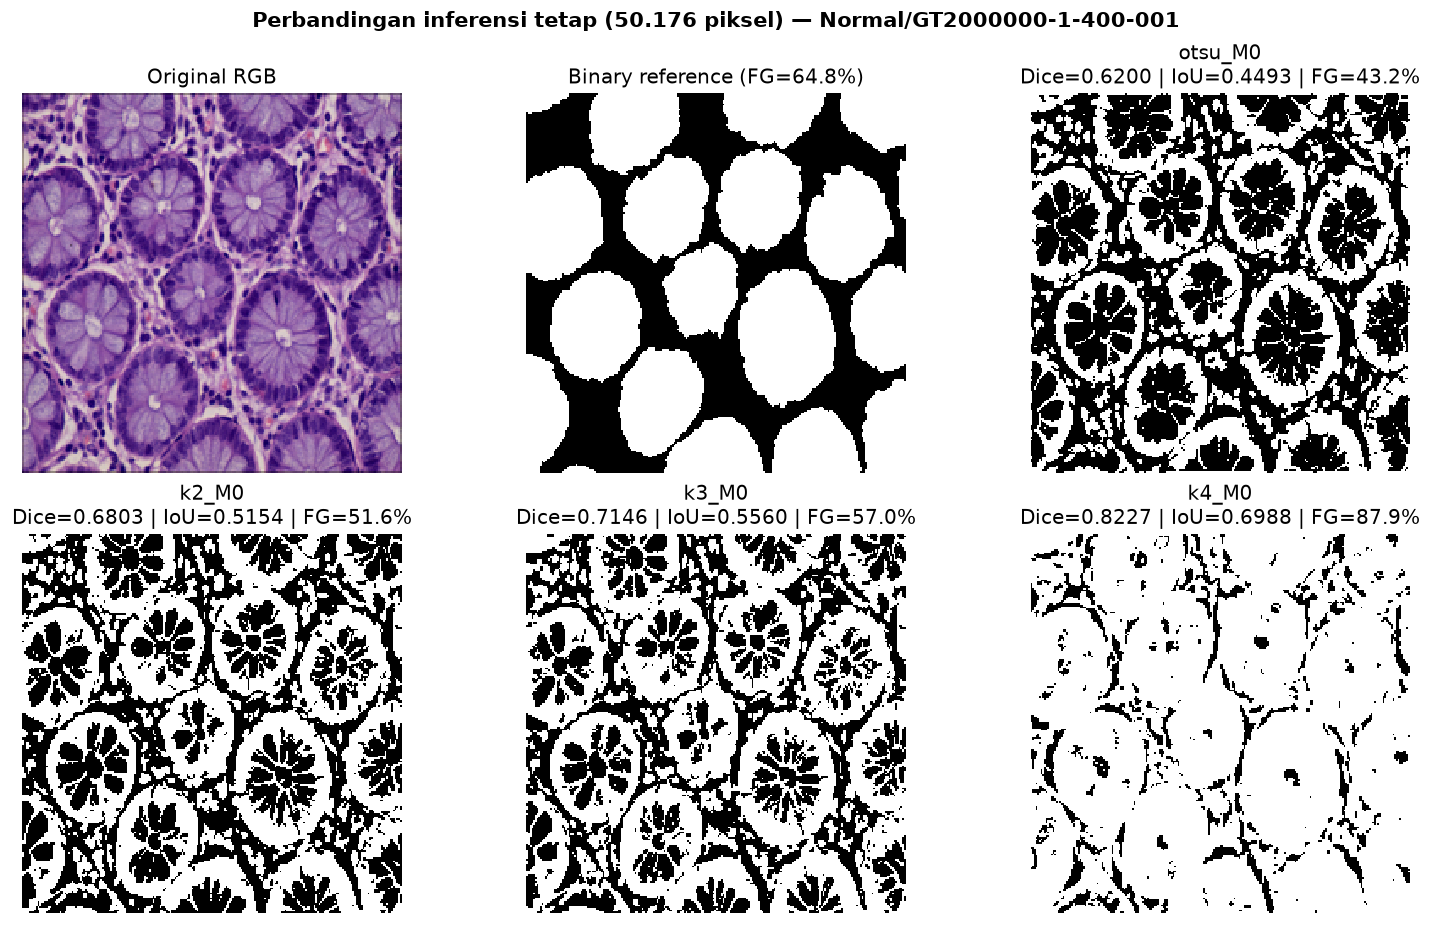

In [4]:
train_rec = split_df.loc[split_df["sample_id"].eq(TRAIN_EXAMPLE_ID)].iloc[0]
assert train_rec["split"] == "train"

if not RAW_AVAILABLE:
    display(Markdown("> **Status citra mentah:** `data/raw/EBHI-SEG/` tidak tersedia; visualisasi kanal Lab dan inferensi contoh dilewati."))
else:
    img = load_rgb(resolve_manifest_path(ROOT, train_rec["image_path"], data_root_override=DATA_ROOT_OVERRIDE))
    ref = load_reference_mask(resolve_manifest_path(ROOT, train_rec["mask_path"], data_root_override=DATA_ROOT_OVERRIDE))
    lab = rgb_to_lab(img)
    lab_edges = compute_shared_lab_edges([lab], bins=64)

    fig_ch, axes_ch = plt.subplots(2, 3, figsize=(13.0, 7.2), layout="constrained")
    axes_ch[0, 0].imshow(img, interpolation="nearest")
    axes_ch[0, 0].set_title(f"Original RGB\n{TRAIN_EXAMPLE_ID}")
    axes_ch[0, 0].axis("off")

    for idx, (ch_name, cmap_name) in enumerate((("L*", "gray"), ("a*", "RdYlGn_r"), ("b*", "PuOr_r"))):
        ax_img = axes_ch[0, idx] if idx > 0 else None
        ch_arr = lab[:, :, idx]
        h_ch = compute_histogram_1d(ch_arr, lab_edges[ch_name])
        ax_h = axes_ch[1, idx]
        ax_h.stairs(h_ch["heights"], h_ch["edges"], fill=True, alpha=0.28, color="#2C3E50")
        ax_h.stairs(h_ch["heights"], h_ch["edges"], color="#2C3E50", linewidth=1.3)
        if ch_name in ("a*", "b*") and float(lab_edges[ch_name][0]) <= 0.0 <= float(lab_edges[ch_name][-1]):
            ax_h.axvline(0.0, color="#888888", linestyle=":", linewidth=1.0)
        ax_h.set_title(f"Histogram fisik {ch_name} (min={ch_arr.min():.1f}, max={ch_arr.max():.1f})")
        ax_h.set_xlabel(f"{ch_name} (float fisik)")
        ax_h.set_ylabel("Jumlah piksel")
        ax_h.grid(axis="y", color="#EAEAEA", linewidth=0.6)

    im_l = axes_ch[0, 1].imshow(lab[:, :, 0], cmap="gray", interpolation="nearest")
    axes_ch[0, 1].set_title("Lab L* (kecerahan fisik)")
    axes_ch[0, 1].axis("off")
    fig_ch.colorbar(im_l, ax=axes_ch[0, 1], shrink=0.8)

    im_a = axes_ch[0, 2].imshow(lab[:, :, 1], cmap="coolwarm", interpolation="nearest")
    axes_ch[0, 2].set_title("Lab a* signed (kroma merah–hijau)")
    axes_ch[0, 2].axis("off")
    fig_ch.colorbar(im_a, ax=axes_ch[0, 2], shrink=0.8)

    export_lab = (ROOT / "reports/figures/04_train_lab_channels_and_hist.png") if EXPORT_FIGURES else None
    finish_figure(fig_ch, export_path=export_lab)

    methods = ("otsu_M0", "k2_M0", "k3_M0", "k4_M0")
    preds = {m: predict_mask(img, m, ROOT) for m in methods}
    fig_p, axes_p = plt.subplots(2, 3, figsize=(12.6, 7.6), layout="constrained")
    axes_p[0, 0].imshow(img, interpolation="nearest")
    axes_p[0, 0].set_title("Original RGB")
    axes_p[0, 1].imshow(ref, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes_p[0, 1].set_title(f"Binary reference (FG={100*ref.mean():.1f}%)")
    for ax, m_id in zip((axes_p[0, 2], axes_p[1, 0], axes_p[1, 1], axes_p[1, 2]), methods):
        d_val, i_val = overlap_scores(preds[m_id], ref)
        ax.imshow(preds[m_id], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{m_id}\nDice={d_val:.4f} | IoU={i_val:.4f} | FG={100*preds[m_id].mean():.1f}%")
    for ax in axes_p.ravel():
        ax.axis("off")
    fig_p.suptitle(f"Perbandingan inferensi tetap (50.176 piksel) — {TRAIN_EXAMPLE_ID}", fontweight="bold")
    export_pred = (ROOT / "reports/figures/04_train_kmeans_predictions.png") if EXPORT_FIGURES else None
    finish_figure(fig_p, export_path=export_pred)

## Ringkasan dan batas metodologis

- **Observasi:** `k=4` memisahkan variasi pewarnaan H&E menjadi tiga *cluster* jaringan berwarna (`[0, 1, 2]`) dan satu *cluster* latar terang-netral (`[3]`), sehingga mencakup sitoplasma pucat yang terlewat oleh `otsu_M0`.
- **Catatan metodologis:** walaupun pembentukan pusat *cluster* bersifat *unsupervised* pada piksel Lab `train`, aturan pemetaan *cluster* ke *foreground* memakai anotasi `train` (`rate >= 0.5`). Saat inferensi pada citra baru, pemetaan tersebut tetap dan tidak pernah membaca *reference* citra target.
- **Keterbatasan:** *mask* hasil K-means memisahkan warna/kecerahan pewarnaan secara global, bukan segmentasi instan nukleus atau kelenjar yang tervalidasi secara patologis.

In [5]:
input_hashes_after = {name: sha256_bytes(path) for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak K-means berubah saat notebook dijalankan."
print("Selesai: provenance model Lab K-means dan pemetaan cluster terverifikasi utuh.")

Selesai: provenance model Lab K-means dan pemetaan cluster terverifikasi utuh.
